# SS3 Part B — STADIOEquities Account Activation


## Project aim

This notebook applies the Random Forest method selected in SS2
to the supplied synthetic STADIOEquities client data.

The business question is:

Among customers who have not activated three days after registration,
can information available at that point predict activation by day 30?

Activation means making a successful first deposit of at least R100
within 30 calendar days of registration.

- Class 0: Not activated within 30 days.
- Class 1: Activated within 30 days.

Low predicted activation probabilities could help prioritise customers
for follow-up. Predictions do not establish whether contacting customers
will cause them to activate.

This notebook examines activation, because the extract does not provide
a suitable six-month dormancy outcome.

In [1]:
import os
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import ParameterGrid

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
LANDMARK_DAYS = 3
HORIZON_DAYS = 30

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Dataset loading

Five datasets are supplied:

1. Registration, KYC and customer information.
2. App and web behaviour.
3. Account funding and activation outcomes.
4. Marketing activity.
5. Data-quality metadata.

The raw registration dataset contains 1,898 rows, including duplicates.
The funding dataset contains 1,893 customers.

The supplied funding labels contain:
- 1,085 non-activated customers: 57.32%.
- 808 activated customers: 42.68%.

These proportions indicate moderate class imbalance.

Behaviour and marketing datasets contain multiple records per customer.
They will be aggregated before joining to customer-level records.

The metadata dataset has no customer identifier, so it is used for
extract information and aggregate quality checks.

In [2]:
data_folder = (
    r"C:\Users\kone\OneDrive - Seriti Business Solutions, Pty (Ltd)"
    r"\Documents\STADIO\CAPS\Capstone_Project_KM"
    r"\Data\stadioequities\stadioequities"
)

results_folder = os.path.join(os.getcwd(), "results")
os.makedirs(results_folder, exist_ok=True)

if not os.path.isdir(data_folder):
    raise FileNotFoundError(
        f"Data folder not found:\n{data_folder}"
    )

print("Data folder found.")
print("\nFiles inside:")

for filename in os.listdir(data_folder):
    print(filename)

Data folder found.

Files inside:
DATA_DICTIONARY.md
README.md
source1_registration_kyc_customer.csv
source2_app_web_behaviour.csv
source3_account_funds_activation.csv
source4_marketing_engagement.csv
source5_data_quality_metadata.csv


In [3]:
files = {
    "registration": "source1_registration_kyc_customer.csv",
    "behaviour": "source2_app_web_behaviour.csv",
    "funding": "source3_account_funds_activation.csv",
    "marketing": "source4_marketing_engagement.csv",
    "metadata": "source5_data_quality_metadata.csv"
}

loaded_data = {}

for name, filename in files.items():
    file_path = os.path.join(data_folder, filename)

    if not os.path.isfile(file_path):
        raise FileNotFoundError(
            f"Required file not found:\n{file_path}"
        )

    loaded_data[name] = pd.read_csv(file_path)

    print(
        f"Loaded {name}: "
        f"{len(loaded_data[name]):,} rows"
    )

raw = loaded_data

print("\nAll five datasets loaded successfully.")

Loaded registration: 1,898 rows
Loaded behaviour: 18,322 rows
Loaded funding: 1,893 rows
Loaded marketing: 8,332 rows
Loaded metadata: 11,475 rows

All five datasets loaded successfully.


In [4]:
inventory = pd.DataFrame([
    {
        "dataset": name,
        "rows": len(df),
        "columns": df.shape[1],
        "exact_duplicates": int(df.duplicated().sum()),
        "unique_customers": (
            df["customer_id"].nunique()
            if "customer_id" in df.columns
            else np.nan
        )
    }
    for name, df in raw.items()
])

display(inventory)

class_counts = (
    raw["funding"]["activation_flag"]
    .value_counts(dropna=False)
)

class_summary = pd.DataFrame({
    "customers": class_counts,
    "percentage": (
        class_counts / len(raw["funding"]) * 100
    ).round(2)
})

display(class_summary)

inventory.to_csv(
    os.path.join(results_folder, "source_inventory.csv"),
    index=False
)

input_hashes = {}

for name, filename in files.items():
    with open(os.path.join(data_folder, filename), "rb") as file:
        input_hashes[name] = hashlib.sha256(
            file.read()
        ).hexdigest()

with open(
    os.path.join(results_folder, "input_sha256.json"), "w"
) as file:
    json.dump(input_hashes, file, indent=2)

,dataset,rows,columns,exact_duplicates,unique_customers
0,registration,1898,13,5,1893.0
1,behaviour,18322,11,0,1893.0
2,funding,1893,11,0,1893.0
3,marketing,8332,10,0,1893.0
4,metadata,11475,5,4,NaN


,customers,percentage
activation_flag,,
False,1085,57.32
True,808,42.68


In [5]:
#Preview each dataset
for name, df in raw.items():
    print(f"\n{name.upper()}")
    print("Columns:", df.columns.tolist())
    display(df.head(3))


REGISTRATION
Columns: ['customer_id', 'registration_date', 'registration_channel', 'acquisition_channel', 'kyc_start_date', 'kyc_completion_date', 'kyc_status', 'kyc_steps_completed', 'onboarding_abandonment_step', 'age', 'region', 'investment_goal', 'risk_appetite']


,customer_id,registration_date,registration_channel,acquisition_channel,kyc_start_date,kyc_completion_date,kyc_status,kyc_steps_completed,onboarding_abandonment_step,age,region,investment_goal,risk_appetite
0,CUST1000000,2025-06-07 17:56:56,Mobile app,Organic search,2025-06-07 22:59:11,2025-06-07 23:39:30,Completed,6,NaN,37.0,Western Cape,Retirement,Moderate
1,CUST1000001,2025-03-22 20:40:55,Mobile app,Referral,2025-03-22 22:56:22,2025-03-23 03:26:48,Completed,6,NaN,18.0,Limpopo,Long-term growth,Moderate
2,CUST1000002,2025-03-12 23:17:29,Web,Organic search,2025-03-13 05:45:28,2025-03-13 07:50:44,Completed,6,NaN,32.0,Gauteng,Savings,Conservative



BEHAVIOUR
Columns: ['session_id', 'customer_id', 'session_start', 'session_duration', 'platform', 'screen_viewed', 'screen_views', 'feature_used', 'onboarding_step', 'abandonment_flag', 'event_timestamp']


,session_id,customer_id,session_start,session_duration,platform,screen_viewed,screen_views,feature_used,onboarding_step,abandonment_flag,event_timestamp
0,SES96368,CUST1000654,2025-12-16 16:21:58,8.0,Web - Mobile,Registration,7,Comparison tool,Risk profile questionnaire,False,2025-12-16 16:27:12
1,SES91185,CUST1000125,2026-07-21 23:50:14,12.3,Web - Mobile,Deposit,7,Education,Proof of address,False,2026-07-21 23:53:41
2,SES91796,CUST1000184,2025-05-15 05:26:53,6.6,Tablet,Deposit confirmation,4,Deposit,Risk profile questionnaire,False,2025-05-15 05:38:14



FUNDING
Columns: ['customer_id', 'first_deposit_date', 'first_deposit_amount', 'deposit_count', 'total_deposited', 'withdrawal_count', 'account_balance', 'balance_as_at', 'activation_flag', 'activation_date', 'days_to_first_deposit']


,customer_id,first_deposit_date,first_deposit_amount,deposit_count,total_deposited,withdrawal_count,account_balance,balance_as_at,activation_flag,activation_date,days_to_first_deposit
0,CUST1000000,2025-06-11 11:52:39,1347.17,5,3500.28,2,3436.94,2026-09-14 09:44:03,True,2025-06-11 11:52:39,3.0
1,CUST1000001,NaN,NaN,0,0.00,0,0.00,2026-09-14 09:44:03,False,NaN,NaN
2,CUST1000002,2025-03-15 01:12:24,666.16,1,666.16,1,507.65,2026-09-14 09:44:03,True,2025-03-15 01:12:24,2.0



MARKETING
Columns: ['customer_id', 'campaign_id', 'campaign_channel', 'campaign_date', 'message_type', 'message_sent', 'message_opened', 'link_clicked', 'nudge_response', 'acquisition_cost']


,customer_id,campaign_id,campaign_channel,campaign_date,message_type,message_sent,message_opened,link_clicked,nudge_response,acquisition_cost
0,CUST1000914,CMP202506045,Push notification,2025-06-01 04:20:06,Promotional offer,True,True,True,False,27.46
1,CUST1001147,CMP202409098,SMS,2024-09-16 02:06:43,Onboarding reminder,True,NaN,NaN,NaN,25.42
2,CUST1001860,CMP202410058,Push notification,2024-10-27 11:36:55,Educational tip,True,True,True,False,37.67



METADATA
Columns: ['record_timestamp', 'source_system', 'record_status', 'missingness_reason', 'data_extraction_date']


,record_timestamp,source_system,record_status,missingness_reason,data_extraction_date
0,2024-10-09 01:15:50,App analytics,Active,Not Applicable,2026-09-14 09:44:03
1,2026-04-24 02:29:14,Marketing automation,Active,Not Applicable,2026-09-14 09:44:03
2,2025-02-06 15:34:19,App analytics,Active,Not Applicable,2026-09-14 09:44:03


## 2. Dataset preprocessing

### Cleaning and eligibility

Exact duplicate records are removed. Text values are standardised,
dates are parsed, and invalid ages are treated as missing.

Date-only registration records are excluded because they do not establish
an exact day-3 prediction time.

Customers must have a complete 30-day follow-up period. Activated records
are checked against the documented deposit rule. Conflicting labels
are excluded rather than silently changed.

Customers who already activated by day 3 are excluded: their activation
outcome is already known when predictions would be made.

### Preventing data leakage

Only information available by day 3 is used as a predictor.

Funding amounts, balances, activation dates and first-deposit dates
are excluded from model inputs. Dates associated with the outcome
are used only to check labels and establish eligibility.

KYC start and completion indicators are reconstructed using timestamps.
Snapshot KYC status and completed-step counts are excluded because
their historical values at day 3 are unavailable.

Behaviour is summarised within the first three days. Marketing features
count messages sent during the same period. Marketing responses are
excluded because response timestamps are unavailable.

Missing SMS tracking is not interpreted as a negative response.
Session duration is excluded because a session could continue beyond
the prediction time.

### Missing values and encoding

Missing numeric values are imputed using training-data medians.
Missing categorical values receive an "unknown" category.
Categorical variables are one-hot encoded inside a modelling pipeline.

Random Forest does not require feature scaling.

### Training, validation and testing

Customers are split chronologically into approximately 60% training,
20% validation and 20% testing.

Outcome-overlap embargoes ensure earlier customers' 30-day outcomes
are available before predictions begin in the next subset.

The final proportions change slightly after these exclusions.

In [6]:
#define cleaning functions
audit = []

def log_check(description, count):
    audit.append({
        "check": description,
        "records": int(count)
    })


def clean_text(series):
    return (
        series.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.casefold()
        .replace("", pd.NA)
    )


def has_time(series):
    return (
        series.astype("string")
        .str.contains(
            r"\d{2}:\d{2}",
            regex=True,
            na=False
        )
    )


def parse_dates(series):
    text = series.astype("string").str.strip()

    is_iso = text.str.match(
        r"^\d{4}[-/]\d{2}[-/]\d{2}",
        na=False
    )

    result = pd.Series(
        pd.NaT,
        index=series.index,
        dtype="datetime64[ns]"
    )

    result.loc[is_iso] = pd.to_datetime(
        text.loc[is_iso],
        format="mixed",
        errors="coerce"
    )

    result.loc[~is_iso] = pd.to_datetime(
        text.loc[~is_iso],
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

    return result

In [7]:
#remove duplicates and standardise text
clean = {}

for name, original in raw.items():
    df = original.drop_duplicates().copy()

    log_check(
        f"{name}: exact duplicates removed",
        len(original) - len(df)
    )

    text_columns = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for column in text_columns:
        is_date_column = (
            column.endswith("_date")
            or column.endswith("_timestamp")
            or column in ["session_start", "balance_as_at"]
        )

        if column != "customer_id" and not is_date_column:
            df[column] = clean_text(df[column])

    if "customer_id" in df.columns:
        df["customer_id"] = (
            df["customer_id"]
            .astype("string")
            .str.strip()
            .str.upper()
        )

    clean[name] = df

reg = clean["registration"].copy()
funds = clean["funding"].copy()
beh = clean["behaviour"].copy()
market = clean["marketing"].copy()
metadata = clean["metadata"].copy()

assert reg["customer_id"].notna().all()
assert funds["customer_id"].notna().all()

assert not reg["customer_id"].duplicated().any(), (
    "Conflicting registration records need investigation."
)

assert not funds["customer_id"].duplicated().any(), (
    "Conflicting funding records need investigation."
)

print("Duplicate removal and text cleaning completed.")

Duplicate removal and text cleaning completed.


In [8]:
#parse dates, target and customer attributes
reg["registration_has_time"] = has_time(
    reg["registration_date"]
)

for column in [
    "registration_date",
    "kyc_start_date",
    "kyc_completion_date"
]:
    reg[column + "_has_time"] = has_time(reg[column])
    reg[column] = parse_dates(reg[column])

for column in [
    "first_deposit_date",
    "activation_date",
    "balance_as_at"
]:
    funds[column + "_has_time"] = has_time(funds[column])
    funds[column] = parse_dates(funds[column])

labels = (
    funds["activation_flag"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": 1,
        "false": 0,
        "1": 1,
        "0": 0
    })
)

assert labels.notna().all(), (
    "Unrecognised activation labels found."
)

funds["target"] = labels.astype(int)

funds["first_deposit_amount"] = pd.to_numeric(
    funds["first_deposit_amount"],
    errors="coerce"
)

extraction_dates = (
    parse_dates(metadata["data_extraction_date"])
    .dropna()
    .unique()
)

assert len(extraction_dates) == 1, (
    "Expected one extraction date."
)

EXTRACT_DATE = pd.Timestamp(extraction_dates[0])

reg["age"] = pd.to_numeric(
    reg["age"],
    errors="coerce"
)

invalid_age = (
    reg["age"].notna()
    & ~reg["age"].between(18, 100)
)

log_check(
    "Invalid ages replaced with missing",
    invalid_age.sum()
)

reg.loc[invalid_age, "age"] = np.nan

allowed_categories = {
    "registration_channel": [
        "mobile app", "web", "tablet app"
    ],
    "acquisition_channel": [
        "paid social", "organic search", "referral",
        "direct", "email", "influencer", "display", "radio"
    ],
    "region": [
        "eastern cape", "free state", "gauteng",
        "kwazulu-natal", "limpopo", "mpumalanga",
        "north west", "northern cape", "western cape"
    ],
    "investment_goal": [
        "long-term growth", "retirement", "short-term gains",
        "savings", "education fund", "income generation"
    ],
    "risk_appetite": [
        "conservative", "moderate", "aggressive"
    ]
}

for column, options in allowed_categories.items():
    invalid = (
        reg[column].notna()
        & ~reg[column].isin(options)
    )

    log_check(
        f"{column}: invalid categories replaced with missing",
        invalid.sum()
    )

    reg.loc[invalid, column] = pd.NA

print("Extraction date:", EXTRACT_DATE)
print("Dates and customer attributes prepared.")

Extraction date: 2026-09-14 09:44:03
Dates and customer attributes prepared.


In [9]:
#check labels and create the eligible cohort
joined = reg.merge(
    funds,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

assert joined["target"].notna().all(), (
    "Some customers could not be matched to their outcome."
)

joined["prediction_time"] = (
    joined["registration_date"]
    + pd.Timedelta(days=LANDMARK_DAYS)
)

joined["outcome_end"] = (
    joined["registration_date"]
    + pd.Timedelta(days=HORIZON_DAYS)
)

registration_ok = (
    joined["registration_date"].notna()
    & joined["registration_has_time"]
)

mature = joined["outcome_end"].le(EXTRACT_DATE)

consistent_positive = (
    joined["first_deposit_date_has_time"]
    & joined["activation_date_has_time"]
    & joined["first_deposit_date"].ge(
        joined["registration_date"]
    )
    & joined["first_deposit_date"].le(
        joined["outcome_end"]
    )
    & joined["first_deposit_amount"].ge(100)
    & joined["activation_date"].eq(
        joined["first_deposit_date"]
    )
)

consistent_negative = (
    joined["target"].eq(0)
    & joined["activation_date"].isna()
    & joined["first_deposit_date"].isna()
)

consistent = (
    joined["target"].eq(1) & consistent_positive
) | consistent_negative

log_check(
    "Insufficient registration timestamps",
    (~registration_ok).sum()
)

log_check(
    "Incomplete outcome windows",
    (~mature).sum()
)

log_check(
    "Conflicting target records excluded",
    (~consistent).sum()
)

cohort_flow = [{
    "step": "Unique registrations",
    "customers": len(joined)
}]

cohort = joined.loc[
    registration_ok & mature & consistent
].copy()

cohort_flow.append({
    "step": "Valid timestamps, follow-up and labels",
    "customers": len(cohort)
})

early_activated = (
    cohort["target"].eq(1)
    & cohort["activation_date"].le(
        cohort["prediction_time"]
    )
)

log_check(
    "Already activated by day 3",
    early_activated.sum()
)

cohort = cohort.loc[~early_activated].copy()

cohort_flow.append({
    "step": "Eligible day-3 cohort",
    "customers": len(cohort)
})

display(pd.DataFrame(cohort_flow))

display(
    cohort["target"]
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_frame()
)

,step,customers
0,Unique registrations,1893
1,"Valid timestamps, follow-up and labels",1861
2,Eligible day-3 cohort,1613


,customers
target,
0,1076
1,537


In [10]:
#reconstruct KYC information available by day 3
for column in [
    "kyc_start_date",
    "kyc_completion_date"
]:
    cohort[column + "_by_day3"] = (
        cohort[column + "_has_time"]
        & cohort[column].ge(
            cohort["registration_date"]
        )
        & cohort[column].le(
            cohort["prediction_time"]
        )
    ).astype(int)

print("KYC indicators created.")

KYC indicators created.


In [11]:
def window_records(df, time_column, source_name):
    events = df.copy()

    events["_has_time"] = has_time(
        events[time_column]
    )

    events["_time"] = parse_dates(
        events[time_column]
    )

    log_check(
        f"{source_name}: insufficient event timestamps",
        (
            ~events["_has_time"]
            | events["_time"].isna()
        ).sum()
    )

    log_check(
        f"{source_name}: unknown customer identifiers",
        (
            ~events["customer_id"].isin(
                reg["customer_id"]
            )
        ).sum()
    )

    events = events.merge(
        cohort[
            [
                "customer_id",
                "registration_date",
                "prediction_time"
            ]
        ],
        on="customer_id",
        how="inner",
        validate="many_to_one"
    )

    keep = (
        events["_has_time"]
        & events["_time"].ge(
            events["registration_date"]
        )
        & events["_time"].le(
            events["prediction_time"]
        )
    )

    log_check(
        f"{source_name}: events retained by day 3",
        keep.sum()
    )

    return events.loc[keep].copy()


behaviour_window = window_records(
    beh,
    "event_timestamp",
    "behaviour"
)

marketing_window = window_records(
    market,
    "campaign_date",
    "marketing"
)

print("Behaviour events retained:", len(behaviour_window))
print("Marketing records retained:", len(marketing_window))

Behaviour events retained: 4452
Marketing records retained: 370


In [12]:
#aggregate behaviour and marketing features

behaviour_window["_abandoned"] = (
    behaviour_window["abandonment_flag"]
    .astype("string")
    .str.casefold()
    .map({"true": 1.0, "false": 0.0})
)

behaviour_summary = (
    behaviour_window
    .groupby("customer_id")
    .agg(
        behaviour_events=("event_timestamp", "size"),
        distinct_sessions=("session_id", "nunique"),
        distinct_screens=("screen_viewed", "nunique"),
        abandonment_events=("_abandoned", "sum")
    )
)

cohort = cohort.merge(
    behaviour_summary,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

behaviour_columns = behaviour_summary.columns.tolist()

cohort[behaviour_columns] = (
    cohort[behaviour_columns].fillna(0)
)

marketing_window["_sent"] = (
    marketing_window["message_sent"]
    .astype("string")
    .str.casefold()
    .map({"true": True, "false": False})
)

sent = marketing_window.loc[
    marketing_window["_sent"].eq(True)
].copy()

sent_counts = (
    sent.groupby("customer_id")
    .size()
    .rename("campaigns_sent")
)

cohort = cohort.merge(
    sent_counts,
    on="customer_id",
    how="left",
    validate="one_to_one"
)

cohort["campaigns_sent"] = (
    cohort["campaigns_sent"].fillna(0)
)

channels = [
    "email",
    "push notification",
    "sms",
    "in-app message",
    "whatsapp"
]

for channel in channels:
    column_name = (
        "sent_"
        + channel.replace(" ", "_").replace("-", "_")
    )

    counts = (
        sent.loc[sent["campaign_channel"].eq(channel)]
        .groupby("customer_id")
        .size()
        .rename(column_name)
    )

    cohort = cohort.merge(
        counts,
        on="customer_id",
        how="left",
        validate="one_to_one"
    )

    cohort[column_name] = (
        cohort[column_name].fillna(0)
    )

print("Customer-level event features created.")

Customer-level event features created.


In [13]:
#define model predictors
cohort["registration_weekday"] = (
    cohort["registration_date"].dt.dayofweek
)

cohort["registration_hour"] = (
    cohort["registration_date"].dt.hour
)

categorical_features = list(allowed_categories)

numeric_features = [
    "age",
    "kyc_start_date_by_day3",
    "kyc_completion_date_by_day3"
] + behaviour_columns + [
    "campaigns_sent",
    "sent_email",
    "sent_push_notification",
    "sent_sms",
    "sent_in_app_message",
    "sent_whatsapp",
    "registration_weekday",
    "registration_hour"
]

FEATURES = numeric_features + categorical_features

# No funding-source column is allowed as a predictor.
assert not set(FEATURES).intersection(
    raw["funding"].columns
), "A funding/outcome field entered the predictors."

for column in categorical_features:
    cohort[column] = (
        cohort[column]
        .astype(object)
        .where(cohort[column].notna(), np.nan)
    )

cohort = (
    cohort.sort_values("registration_date")
    .reset_index(drop=True)
)

print("Number of predictors:", len(FEATURES))
print("\nPredictors:")

for feature in FEATURES:
    print(feature)

Number of predictors: 20

Predictors:
age
kyc_start_date_by_day3
kyc_completion_date_by_day3
behaviour_events
distinct_sessions
distinct_screens
abandonment_events
campaigns_sent
sent_email
sent_push_notification
sent_sms
sent_in_app_message
sent_whatsapp
registration_weekday
registration_hour
registration_channel
acquisition_channel
region
investment_goal
risk_appetite


In [14]:
n = len(cohort)

assert n > 100, "Too few eligible customers."

validation_start = (
    cohort.iloc[int(0.60 * n)]["registration_date"]
    .normalize()
)

test_start = (
    cohort.iloc[int(0.80 * n)]["registration_date"]
    .normalize()
)

train_mask = (
    cohort["registration_date"] < validation_start
)

validation_mask = (
    (cohort["registration_date"] >= validation_start)
    & (cohort["registration_date"] < test_start)
)

test_mask = (
    cohort["registration_date"] >= test_start
)

first_validation_prediction = (
    cohort.loc[validation_mask, "prediction_time"].min()
)

first_test_prediction = (
    cohort.loc[test_mask, "prediction_time"].min()
)

train_embargo = (
    train_mask
    & cohort["outcome_end"].ge(
        first_validation_prediction
    )
)

validation_embargo = (
    validation_mask
    & cohort["outcome_end"].ge(
        first_test_prediction
    )
)

log_check(
    "Training outcome-overlap embargo",
    train_embargo.sum()
)

log_check(
    "Validation outcome-overlap embargo",
    validation_embargo.sum()
)

train_mask = train_mask & ~train_embargo
validation_mask = validation_mask & ~validation_embargo

subsets = {
    "training": cohort.loc[train_mask].copy(),
    "validation": cohort.loc[validation_mask].copy(),
    "testing": cohort.loc[test_mask].copy()
}

assert (
    subsets["training"]["outcome_end"].max()
    < first_validation_prediction
)

assert (
    subsets["validation"]["outcome_end"].max()
    < first_test_prediction
)

for name, frame in subsets.items():
    assert frame["target"].nunique() == 2, (
        f"{name} must contain both classes."
    )

# Verify that customer identifiers do not overlap.
subset_names = list(subsets)

for i, name_a in enumerate(subset_names):
    for name_b in subset_names[i + 1:]:
        assert set(
            subsets[name_a]["customer_id"]
        ).isdisjoint(
            subsets[name_b]["customer_id"]
        )

split_summary = pd.DataFrame([
    {
        "subset": name,
        "customers": len(frame),
        "not_activated": int(frame["target"].eq(0).sum()),
        "activated": int(frame["target"].eq(1).sum()),
        "activation_rate": frame["target"].mean(),
        "start": frame["registration_date"].min(),
        "end": frame["registration_date"].max()
    }
    for name, frame in subsets.items()
])

display(split_summary)

X_train = subsets["training"][FEATURES]
y_train = subsets["training"]["target"]

X_val = subsets["validation"][FEATURES]
y_val = subsets["validation"]["target"]

X_test = subsets["testing"][FEATURES]
y_test = subsets["testing"]["target"]

display(pd.DataFrame(audit))

print("\nMetadata status counts:")
display(metadata["record_status"].value_counts())

split_summary.to_csv(
    os.path.join(results_folder, "split_summary.csv"),
    index=False
)

pd.DataFrame(audit).to_csv(
    os.path.join(results_folder, "quality_audit.csv"),
    index=False
)

pd.DataFrame(cohort_flow).to_csv(
    os.path.join(results_folder, "cohort_flow.csv"),
    index=False
)

,subset,customers,not_activated,activated,activation_rate,start,end
0,training,900,605,295,0.327778,2024-09-01 11:41:50,2025-09-25 03:48:27
1,validation,273,180,93,0.340659,2025-10-22 05:57:36,2026-02-24 17:38:56
2,testing,323,210,113,0.349845,2026-03-24 00:22:46,2026-08-13 15:34:42


,check,records
0,registration: exact duplicates removed,5
1,behaviour: exact duplicates removed,0
2,funding: exact duplicates removed,0
3,marketing: exact duplicates removed,0
4,metadata: exact duplicates removed,4
5,Invalid ages replaced with missing,0
6,registration_channel: invalid categories repla...,0
7,acquisition_channel: invalid categories replac...,0
8,region: invalid categories replaced with missing,0
9,investment_goal: invalid categories replaced w...,0



Metadata status counts:


record_status
active        11250
superseded       84
corrected        73
deleted          64
Name: count, dtype: int64[pyarrow]

## 3. Model training

Random Forest retains the model family selected in SS2. It can model
non-linear relationships and interactions in tabular customer data.

### Hyperparameter choices

- 300 trees: a computationally manageable starting point that reduces
  reliance on individual trees. This is not claimed to be optimal.
- Maximum depth of 8 or unrestricted: compares restricted and more
  flexible trees.
- Minimum leaf sizes of 3 or 10: compares different amounts of smoothing
  and limits very small leaves.
- Maximum features of square root or 70%: varies feature diversity
  between trees.
- Balanced class weights: accounts for class imbalance using the
  labels available during fitting.
- Random seed of 42: supports reproducibility.
- Two parallel jobs: limits computing resource use.

Eight combinations are compared using validation macro F1 at a
probability threshold of 0.5.

After choosing the configuration, a threshold is selected using
validation macro F1. Macro F1 gives both classes equal importance.

The test data are not used to select hyperparameters or the threshold.
No learning rate, optimiser or number of epochs applies to Random Forest.

SMOTE is not used. Class weighting avoids generating synthetic mixtures
of encoded categorical records.

In [15]:
#define the preprocessing and model pipeline
def make_pipeline(parameters):
    numeric_transformer = SimpleImputer(
        strategy="median",
        add_indicator=True
    )

    categorical_transformer = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="unknown"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    preprocessor = ColumnTransformer([
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ])

    classifier = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=2,
        **parameters
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", classifier)
    ])

In [16]:
parameter_grid = list(ParameterGrid({
    "max_depth": [8, None],
    "min_samples_leaf": [3, 10],
    "max_features": ["sqrt", 0.7]
}))

records = []
candidate_models = []

for index, parameters in enumerate(parameter_grid):
    candidate = make_pipeline(parameters)

    candidate.fit(X_train, y_train)

    training_prediction = candidate.predict(X_train)
    validation_prediction = candidate.predict(X_val)

    records.append({
        "candidate": index,
        **parameters,
        "training_macro_f1": f1_score(
            y_train,
            training_prediction,
            average="macro"
        ),
        "validation_macro_f1": f1_score(
            y_val,
            validation_prediction,
            average="macro"
        )
    })

    candidate_models.append(candidate)

    print(
        f"Completed candidate "
        f"{index + 1}/{len(parameter_grid)}"
    )

search_results = pd.DataFrame(records)

# Tie-breaking favours shallower trees, larger leaves
# and the smaller feature subset.
best_index = min(
    range(len(records)),
    key=lambda i: (
        -records[i]["validation_macro_f1"],
        (
            records[i]["max_depth"]
            if records[i]["max_depth"] is not None
            else float("inf")
        ),
        -records[i]["min_samples_leaf"],
        (
            0
            if records[i]["max_features"] == "sqrt"
            else 1
        )
    )
)

selected_parameters = parameter_grid[best_index]
selected_model = candidate_models[best_index]

display(search_results)

print("Selected parameters:", selected_parameters)

search_results.to_csv(
    os.path.join(
        results_folder,
        "hyperparameter_validation.csv"
    ),
    index=False
)

Completed candidate 1/8
Completed candidate 2/8
Completed candidate 3/8
Completed candidate 4/8
Completed candidate 5/8
Completed candidate 6/8
Completed candidate 7/8
Completed candidate 8/8


,candidate,max_depth,max_features,min_samples_leaf,training_macro_f1,validation_macro_f1
0,0,8.0,sqrt,3,0.832253,0.840591
1,1,8.0,sqrt,10,0.821483,0.833463
2,2,8.0,0.7,3,0.857403,0.844163
3,3,8.0,0.7,10,0.829017,0.837024
4,4,NaN,sqrt,3,0.869349,0.847741
5,5,NaN,sqrt,10,0.822558,0.833463
6,6,NaN,0.7,3,0.909879,0.843220
7,7,NaN,0.7,10,0.832253,0.837024


Selected parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3}


In [17]:
validation_probability = (
    selected_model.predict_proba(X_val)[:, 1]
)

thresholds = np.round(
    np.arange(0.10, 0.901, 0.01),
    2
)

threshold_scores = np.array([
    f1_score(
        y_val,
        (validation_probability >= threshold).astype(int),
        average="macro"
    )
    for threshold in thresholds
])

tied_indices = np.flatnonzero(
    np.isclose(
        threshold_scores,
        threshold_scores.max()
    )
)

best_threshold_index = min(
    tied_indices,
    key=lambda i: abs(thresholds[i] - 0.5)
)

THRESHOLD = float(
    thresholds[best_threshold_index]
)

print("Selected activation threshold:", THRESHOLD)
print(
    "Validation macro F1:",
    round(float(threshold_scores[best_threshold_index]), 4)
)

threshold_results = pd.DataFrame({
    "threshold": thresholds,
    "validation_macro_f1": threshold_scores
})

threshold_results.to_csv(
    os.path.join(
        results_folder,
        "threshold_validation.csv"
    ),
    index=False
)

settings = {
    "model": "RandomForestClassifier",
    "n_estimators": 300,
    "class_weight": "balanced",
    "random_state": RANDOM_STATE,
    **selected_parameters,
    "threshold": THRESHOLD,
    "features": FEATURES
}

with open(
    os.path.join(results_folder, "selected_settings.json"),
    "w"
) as file:
    json.dump(settings, file, indent=2)

Selected activation threshold: 0.58
Validation macro F1: 0.8488


## 4. Model validation

Validation data were unseen during candidate fitting, but were used
to select the model and threshold. Their scores therefore represent
development performance rather than an independent final estimate.

After freezing the configuration and threshold, a fresh pipeline is
fitted on training plus validation data.

The chronological test set is then evaluated without further tuning.

The following metrics are reported:

- Accuracy.
- Balanced accuracy.
- Macro and weighted F1.
- Recall for each class.
- ROC-AUC.
- Average precision for the activated class.
- Brier score.

Non-activation recall is particularly relevant when prioritising
customers who may need assistance.

The model is compared with a majority-class baseline and a constant
activation-probability baseline. Baseline outputs are determined using
development data only.

A bootstrap interval describes uncertainty in test macro F1 conditional
on the fitted model. It assumes independent customers and does not
capture temporal dependence or retraining uncertainty.

In [18]:
def calculate_metrics(name, actual, probability):
    prediction = (
        probability >= THRESHOLD
    ).astype(int)

    return {
        "subset": name,
        "customers": len(actual),
        "accuracy": accuracy_score(
            actual, prediction
        ),
        "balanced_accuracy": balanced_accuracy_score(
            actual, prediction
        ),
        "macro_f1": f1_score(
            actual, prediction, average="macro"
        ),
        "weighted_f1": f1_score(
            actual, prediction, average="weighted"
        ),
        "nonactivation_recall": recall_score(
            actual, prediction, pos_label=0
        ),
        "activation_recall": recall_score(
            actual, prediction, pos_label=1
        ),
        "roc_auc": roc_auc_score(
            actual, probability
        ),
        "average_precision": average_precision_score(
            actual, probability
        ),
        "brier_score": brier_score_loss(
            actual, probability
        )
    }


validation_metrics = calculate_metrics(
    "Validation used for selection",
    y_val,
    validation_probability
)

X_development = pd.concat(
    [X_train, X_val],
    ignore_index=True
)

y_development = pd.concat(
    [y_train, y_val],
    ignore_index=True
)

final_model = make_pipeline(selected_parameters)

final_model.fit(
    X_development,
    y_development
)

development_probability = (
    final_model.predict_proba(X_development)[:, 1]
)

test_probability = (
    final_model.predict_proba(X_test)[:, 1]
)

test_prediction = (
    test_probability >= THRESHOLD
).astype(int)

metric_table = pd.DataFrame([
    calculate_metrics(
        "Development resubstitution",
        y_development,
        development_probability
    ),
    validation_metrics,
    calculate_metrics(
        "Untouched chronological test",
        y_test,
        test_probability
    )
])

display(metric_table.round(4))

metric_table.to_csv(
    os.path.join(results_folder, "metrics.csv"),
    index=False
)

,subset,customers,accuracy,balanced_accuracy,macro_f1,weighted_f1,nonactivation_recall,activation_recall,roc_auc,average_precision,brier_score
0,Development resubstitution,1173,0.9258,0.9381,0.9195,0.9271,0.9019,0.9742,0.9915,0.9863,0.0719
1,Validation used for selection,273,0.8571,0.8709,0.8488,0.8601,0.8278,0.9140,0.8980,0.7851,0.1137
2,Untouched chronological test,323,0.8700,0.8816,0.8630,0.8723,0.8429,0.9204,0.9276,0.8310,0.1008


In [19]:
majority_class = int(
    y_development.mode().iloc[0]
)

majority_prediction = np.full(
    len(y_test),
    majority_class
)

baseline_probability = np.full(
    len(y_test),
    y_development.mean()
)

baseline_accuracy = accuracy_score(
    y_test,
    majority_prediction
)

baseline_macro_f1 = f1_score(
    y_test,
    majority_prediction,
    average="macro",
    zero_division=0
)

baseline_brier = brier_score_loss(
    y_test,
    baseline_probability
)

print(
    "Majority baseline accuracy:",
    round(baseline_accuracy, 4)
)

print(
    "Majority baseline macro F1:",
    round(baseline_macro_f1, 4)
)

print(
    "Constant-probability baseline Brier:",
    round(baseline_brier, 4)
)

report = classification_report(
    y_test,
    test_prediction,
    labels=[0, 1],
    target_names=["Not activated", "Activated"],
    zero_division=0,
    output_dict=True
)

display(pd.DataFrame(report).round(4))

pd.DataFrame(report).to_csv(
    os.path.join(
        results_folder,
        "test_classification_report.csv"
    )
)

Majority baseline accuracy: 0.6502
Majority baseline macro F1: 0.394
Constant-probability baseline Brier: 0.2278


,Not activated,Activated,accuracy,macro avg,weighted avg
precision,0.9516,0.7591,0.87,0.8554,0.8843
recall,0.8429,0.9204,0.87,0.8816,0.8700
f1-score,0.8939,0.8320,0.87,0.8630,0.8723
support,210.0000,113.0000,0.87,323.0000,323.0000


In [20]:
rng = np.random.default_rng(RANDOM_STATE)

actual_array = y_test.to_numpy()
bootstrap_scores = []

for _ in range(1000):
    indices = rng.integers(
        0,
        len(actual_array),
        size=len(actual_array)
    )

    if np.unique(actual_array[indices]).size == 2:
        score = f1_score(
            actual_array[indices],
            test_prediction[indices],
            average="macro",
            zero_division=0
        )

        bootstrap_scores.append(score)

confidence_interval = np.quantile(
    bootstrap_scores,
    [0.025, 0.975]
)

print(
    "Conditional 95% bootstrap interval for test macro F1:",
    np.round(confidence_interval, 4)
)

uncertainty_results = {
    "bootstrap_replicates": len(bootstrap_scores),
    "macro_f1_ci95": confidence_interval.tolist(),
    "majority_baseline_accuracy": float(baseline_accuracy),
    "majority_baseline_macro_f1": float(baseline_macro_f1),
    "probability_baseline_brier": float(baseline_brier)
}

with open(
    os.path.join(results_folder, "test_uncertainty.json"),
    "w"
) as file:
    json.dump(uncertainty_results, file, indent=2)

Conditional 95% bootstrap interval for test macro F1: [0.8246 0.9009]


## 5. Results visualisation

The following plots show:

1. Training and validation performance across model configurations.
2. Validation-based threshold selection.
3. Development, validation and test performance.
4. The test confusion matrix.
5. Test ROC and precision-recall curves.
6. Test probability calibration.
7. Test class-specific metrics.
8. Class proportions across chronological subsets.
9. Random Forest feature importance.

Development scores are resubstitution estimates: the final model has
already seen those customers during fitting.

Validation scores were used for selection. The chronological test
provides the final independent evaluation.

Feature importance describes how the model uses predictors.
It does not demonstrate that changing a feature causes activation.
Impurity importance can favour continuous or high-cardinality features.

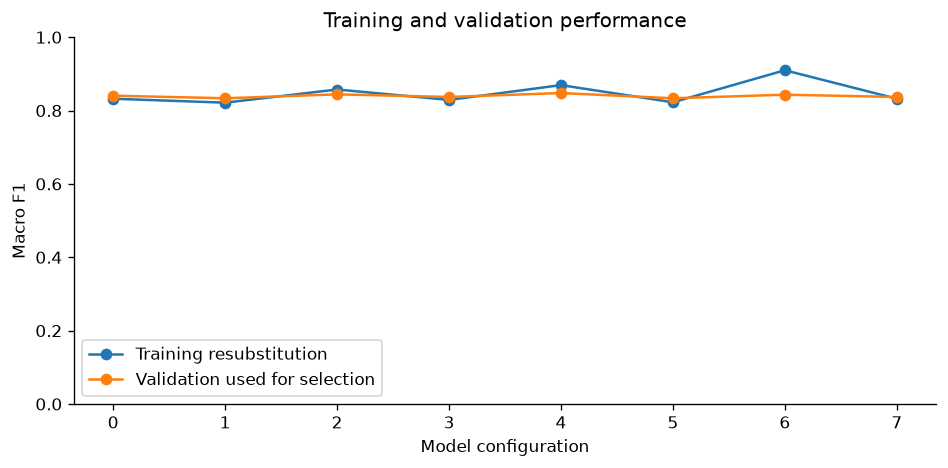

In [21]:
#plotting settings and training versus validation
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10
})


def save_figure(filename):
    plt.tight_layout()

    plt.savefig(
        os.path.join(results_folder, filename),
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    search_results["candidate"],
    search_results["training_macro_f1"],
    "o-",
    label="Training resubstitution"
)

ax.plot(
    search_results["candidate"],
    search_results["validation_macro_f1"],
    "o-",
    label="Validation used for selection"
)

ax.set(
    xlabel="Model configuration",
    ylabel="Macro F1",
    title="Training and validation performance",
    ylim=(0, 1)
)

ax.legend()

save_figure("01_training_validation.png")

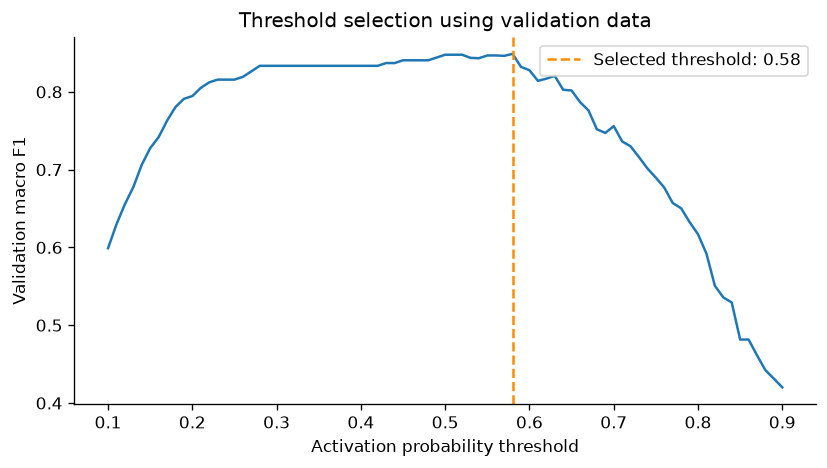

In [22]:
#threshold-selection plot
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    thresholds,
    threshold_scores
)

ax.axvline(
    THRESHOLD,
    color="darkorange",
    linestyle="--",
    label=f"Selected threshold: {THRESHOLD:.2f}"
)

ax.set(
    xlabel="Activation probability threshold",
    ylabel="Validation macro F1",
    title="Threshold selection using validation data"
)

ax.legend()

save_figure("02_threshold_selection.png")

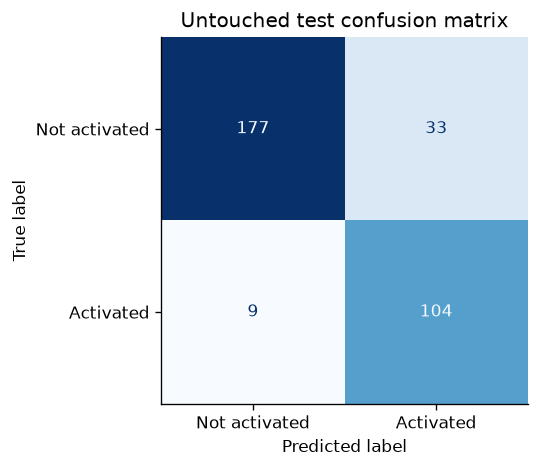

In [23]:
#test confusion matrix
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_prediction,
    labels=[0, 1],
    display_labels=["Not activated", "Activated"],
    cmap="Blues",
    colorbar=False,
    ax=ax
)

ax.set_title("Untouched test confusion matrix")

save_figure("04_test_confusion_matrix.png")

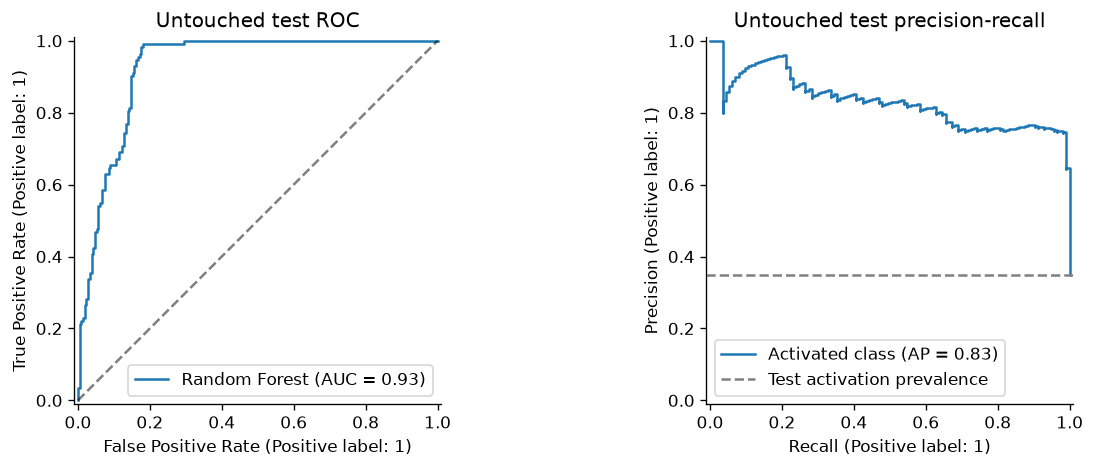

In [24]:
#test ROC and precision-recall curves
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4)
)

RocCurveDisplay.from_predictions(
    y_test,
    test_probability,
    name="Random Forest",
    ax=axes[0]
)

axes[0].plot(
    [0, 1],
    [0, 1],
    "k--",
    alpha=0.5
)

axes[0].set_title("Untouched test ROC")

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probability,
    name="Activated class",
    ax=axes[1]
)

axes[1].axhline(
    y_test.mean(),
    color="grey",
    linestyle="--",
    label="Test activation prevalence"
)

axes[1].set_title("Untouched test precision-recall")
axes[1].legend()

save_figure("05_test_roc_precision_recall.png")

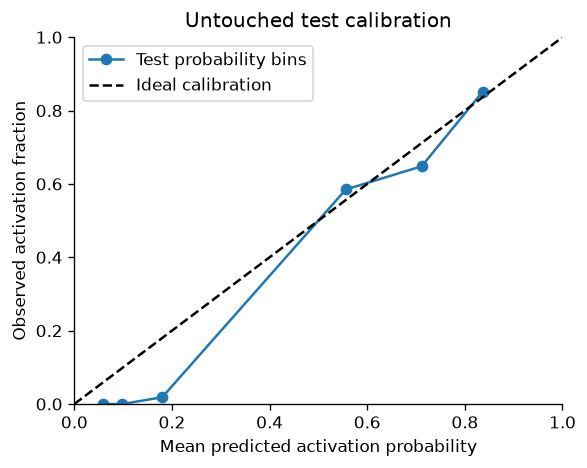

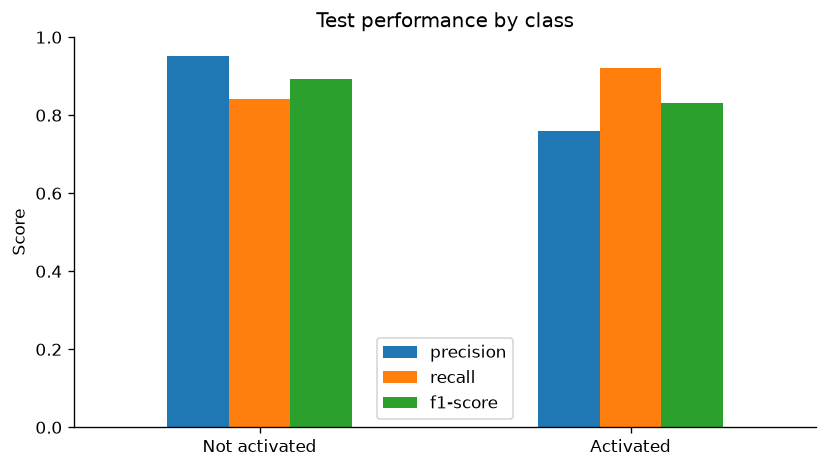

In [25]:
#calibration and class-specific metrics
observed_fraction, mean_probability = calibration_curve(
    y_test,
    test_probability,
    n_bins=6,
    strategy="quantile"
)

fig, ax = plt.subplots(figsize=(5, 4))

ax.plot(
    mean_probability,
    observed_fraction,
    "o-",
    label="Test probability bins"
)

ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Ideal calibration"
)

ax.set(
    xlabel="Mean predicted activation probability",
    ylabel="Observed activation fraction",
    title="Untouched test calibration",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.legend()

save_figure("06_test_calibration.png")


class_metrics = pd.DataFrame({
    name: report[name]
    for name in ["Not activated", "Activated"]
}).T[
    ["precision", "recall", "f1-score"]
]

fig, ax = plt.subplots(figsize=(7, 4))

class_metrics.plot.bar(
    ax=ax,
    rot=0
)

ax.set(
    xlabel="",
    ylabel="Score",
    ylim=(0, 1),
    title="Test performance by class"
)

save_figure("07_test_class_metrics.png")

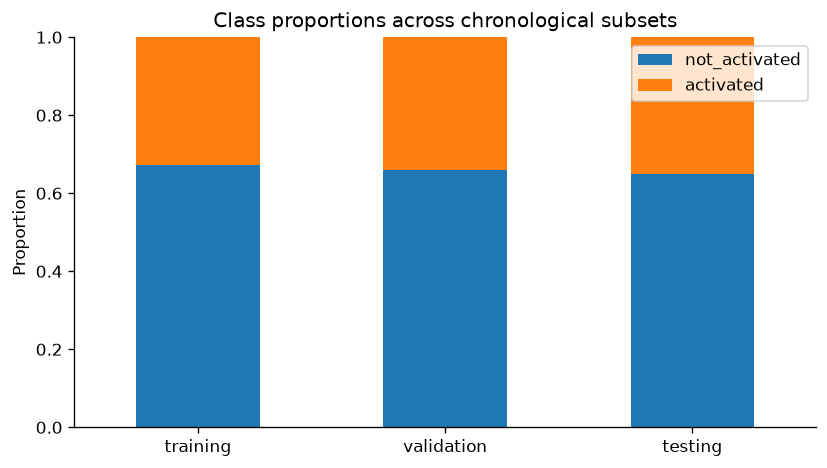

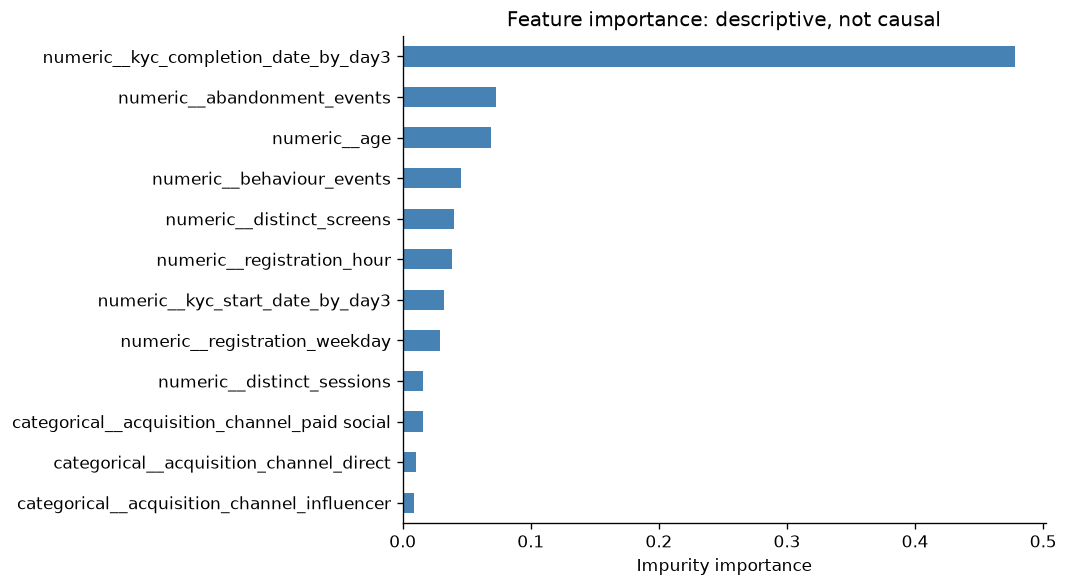

In [26]:
#subset class proportions and feature importance
class_counts_by_subset = (
    split_summary
    .set_index("subset")[
        ["not_activated", "activated"]
    ]
)

class_proportions = class_counts_by_subset.div(
    class_counts_by_subset.sum(axis=1),
    axis=0
)

fig, ax = plt.subplots(figsize=(7, 4))

class_proportions.plot.bar(
    stacked=True,
    ax=ax,
    rot=0
)

ax.set(
    xlabel="",
    ylabel="Proportion",
    ylim=(0, 1),
    title="Class proportions across chronological subsets"
)

save_figure("08_subset_class_proportions.png")


feature_names = (
    final_model.named_steps["preprocess"]
    .get_feature_names_out()
)

importance = pd.Series(
    final_model.named_steps["model"].feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importance.rename(
    "impurity_importance"
).to_csv(
    os.path.join(
        results_folder,
        "feature_importance.csv"
    )
)

fig, ax = plt.subplots(figsize=(9, 5))

importance.head(12).sort_values().plot.barh(
    ax=ax,
    color="steelblue"
)

ax.set(
    xlabel="Impurity importance",
    title="Feature importance: descriptive, not causal"
)

save_figure("09_feature_importance.png")

In [27]:
#calculate the business interpretation
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_prediction,
    labels=[0, 1]
).ravel()

test_results = metric_table.iloc[2]

print("FINAL TEST RESULTS")
print("------------------")

print(
    f"Accuracy: "
    f"{test_results['accuracy']:.2%}"
)

print(
    f"Balanced accuracy: "
    f"{test_results['balanced_accuracy']:.2%}"
)

print(
    f"Macro F1: "
    f"{test_results['macro_f1']:.4f}"
)

print(
    f"ROC-AUC: "
    f"{test_results['roc_auc']:.4f}"
)

print(
    f"\nNon-activators identified: "
    f"{tn} out of {tn + fp}"
)

print(f"Non-activators missed: {fp}")

print(
    f"Eventual activators also prioritised for follow-up: {fn}"
)

print(
    f"Total customers prioritised for follow-up: {tn + fn}"
)

print(
    "\nThese results describe prediction on synthetic data. "
    "They do not demonstrate that an intervention increases activation."
)

print("\nSaved results folder:", results_folder)

FINAL TEST RESULTS
------------------
Accuracy: 87.00%
Balanced accuracy: 88.16%
Macro F1: 0.8630
ROC-AUC: 0.9276

Non-activators identified: 177 out of 210
Non-activators missed: 33
Eventual activators also prioritised for follow-up: 9
Total customers prioritised for follow-up: 186

These results describe prediction on synthetic data. They do not demonstrate that an intervention increases activation.

Saved results folder: C:\Users\kone\OneDrive - Seriti Business Solutions, Pty (Ltd)\Documents\STADIO\CAPS\Capstone_Project_KM\results
